In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from pathlib import Path
Path('Charts').mkdir(exist_ok=True)
df = pd.read_excel('D.xlsx', sheet_name='Insurance')
print('Shape:', df.shape)
print(df.head())
print('Missing values:')
print(df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

Shape: (1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
Duplicate rows: 1


In [4]:
import pandas as pd

df = pd.read_excel('D.xlsx')

def descriptive_statistics(sample, field):
    return sample[field].describe()

random_sample = df.sample(n=150, random_state=42)

print('Random sample size:', len(random_sample))
print(descriptive_statistics(random_sample, 'charges'))

Random sample size: 150
count      150.000000
mean     13010.715697
std      11916.853846
min       1131.506600
25%       4727.569912
50%       8702.953700
75%      18179.938500
max      48673.558800
Name: charges, dtype: float64


In [6]:
systematic_sample = df.iloc[::9]

print('Systematic sample size:', len(systematic_sample))
print(systematic_sample['charges'].describe())

Systematic sample size: 149
count      149.000000
mean     13317.838502
std      11335.692567
min       1241.565000
25%       5709.164400
50%      10085.846000
75%      17081.080000
max      55135.402090
Name: charges, dtype: float64


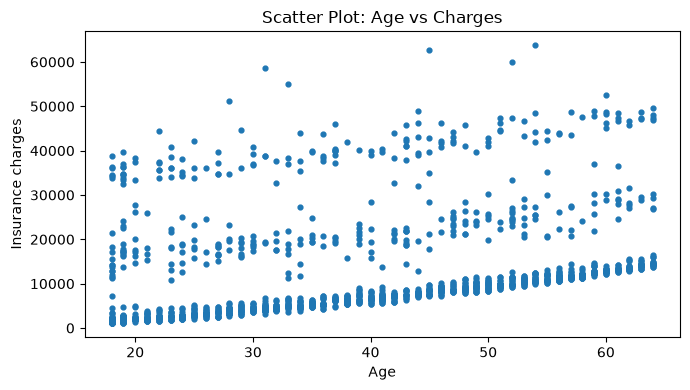

In [7]:
plt.figure(figsize=(7, 4))
plt.scatter(df['age'], df['charges'], s=12)
plt.xlabel('Age')
plt.ylabel('Insurance charges')
plt.title('Scatter Plot: Age vs Charges')
plt.tight_layout()
plt.savefig('Charts/01_scatter.png', dpi=150)
plt.show()

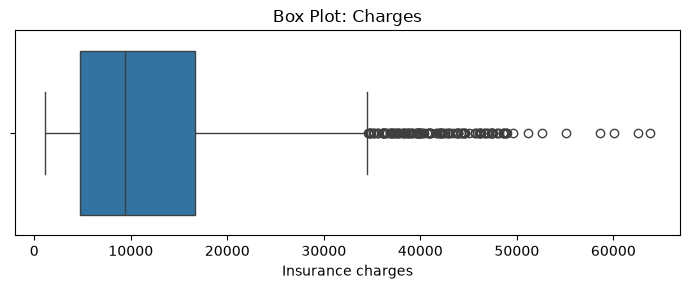

In [9]:
plt.figure(figsize=(7, 3))
sns.boxplot(x=df['charges'])
plt.xlabel('Insurance charges')
plt.title('Box Plot: Charges')
plt.tight_layout()
plt.savefig('Charts/02_boxplot.png', dpi=150)
plt.show()

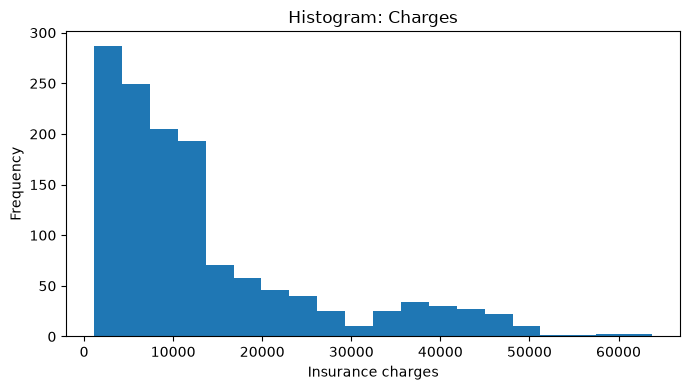

In [10]:
plt.figure(figsize=(7, 4))
plt.hist(df['charges'], bins=20)
plt.xlabel('Insurance charges')
plt.ylabel('Frequency')
plt.title('Histogram: Charges')
plt.tight_layout()
plt.savefig('Charts/03_histogram.png', dpi=150)
plt.show()

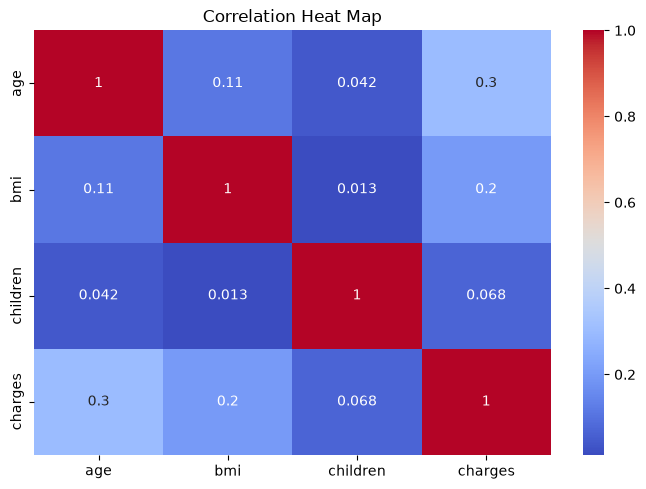

In [11]:
correlation = df[['age', 'bmi', 'children', 'charges']].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heat Map')
plt.tight_layout()
plt.savefig('Charts/04_heatmap.png', dpi=150)
plt.show()

In [12]:
pearson_r, pearson_p = stats.pearsonr(df['age'], df['charges'])
spearman_r, spearman_p = stats.spearmanr(df['age'], df['charges'])
print('Pearson r:', pearson_r, 'p-value:', pearson_p)
print('Spearman rho:', spearman_r, 'p-value:', spearman_p)

Pearson r: 0.29900819333064754 p-value: 4.886693331718191e-29
Spearman rho: 0.5343921337718459 p-value: 1.130692027803595e-99


In [13]:
frequency_table = pd.crosstab(df['smoker'], df['region'])
chi2, chi_p, dof, expected = stats.chi2_contingency(frequency_table)
print(frequency_table)
print('Chi-square:', chi2, 'p-value:', chi_p, 'df:', dof)
print('Minimum expected frequency:', expected.min())

region  northeast  northwest  southeast  southwest
smoker                                            
no            257        267        273        267
yes            67         58         91         58
Chi-square: 7.34347776140707 p-value: 0.06171954839170546 df: 3
Minimum expected frequency: 66.34977578475336


In [14]:
population_mean = df['charges'].mean()
shapiro_stat, shapiro_p = stats.shapiro(random_sample['charges'])
t_stat, t_p = stats.ttest_1samp(random_sample['charges'], population_mean)
print('Full dataset mean:', population_mean)
print('Random sample mean:', random_sample['charges'].mean())
print('Shapiro statistic and p-value:', shapiro_stat, shapiro_p)
print('One-sample t-statistic and p-value:', t_stat, t_p)

Full dataset mean: 13270.422265141257
Random sample mean: 13010.715697466665
Shapiro statistic and p-value: 0.8178476702574179 2.2110385197997617e-12
One-sample t-statistic and p-value: -0.266911292977639 0.7899065162158013
